In [1]:
pip install yfinance

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ---------- ----------------------------- 0.5/2.0 MB 1.1 MB/s eta 0:00:02
   --------------- ------------------------ 0.8/2.0 MB 902.1 kB/s eta 0:00:02
   --------------------- ------------------ 1.0/2.0 MB 1.0 MB/s eta 0:00:01
   --------------------- ------------------ 1.0/2.0 MB 1.0 MB/s eta 0:00:01
   -------------------------- ------------- 1.3/2.0 MB 946.8 kB/s eta 0:00:01
   ------------------------------- -------- 1.6/2.0 MB 1.0 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 1.1 MB/s  0:00:01

   -------- ------------------------------- 1/5 [websockets]
   -------- ------------------------------- 1/5 [websockets]
   ---------------- ----------------------- 2/5 [peewee]
   ---------------- ----------------------- 2/5 [peewee]
   --------------------

In [2]:
from datetime import date, timedelta

days =100

today = date.today()
end_date = today.strftime("%Y-%m-%d")


star_date = today - timedelta(days=days)
star_date = star_date.strftime("%Y-%m-%d")



In [5]:
import yfinance as yf
import pandas as pd

data = yf.download('BTC-USD', start=star_date, end=end_date , progress=False)

data

Price,Close,High,Low,Open,Volume
Ticker,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD
Date,,,,,
2026-06-11,63561.054688,63851.949219,61447.968750,61448.878906,29316677897
2026-06-12,63543.199219,64334.015625,62778.792969,63547.441406,26881868307
2026-06-13,64421.324219,64700.878906,63431.320312,63541.515625,16956245530
2026-06-14,65710.398438,65749.781250,63634.023438,64420.167969,21572226975
2026-06-15,66289.500000,67248.132812,65315.835938,65711.109375,32927321950
...,...,...,...,...,...
2026-09-14,78163.382812,79568.953125,76367.375000,76830.281250,29909358382
2026-09-15,75612.507812,78242.546875,74944.593750,78162.484375,39694675220


In [6]:
data["Date"] = data.index
data.reset_index(drop=True , inplace=True)
data


Price,Close,High,Low,Open,Volume,Date
Ticker,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD,
0,63561.054688,63851.949219,61447.968750,61448.878906,29316677897,2026-06-11
1,63543.199219,64334.015625,62778.792969,63547.441406,26881868307,2026-06-12
2,64421.324219,64700.878906,63431.320312,63541.515625,16956245530,2026-06-13
3,65710.398438,65749.781250,63634.023438,64420.167969,21572226975,2026-06-14
4,66289.500000,67248.132812,65315.835938,65711.109375,32927321950,2026-06-15
...,...,...,...,...,...,...
95,78163.382812,79568.953125,76367.375000,76830.281250,29909358382,2026-09-14
96,75612.507812,78242.546875,74944.593750,78162.484375,39694675220,2026-09-15
97,76150.320312,76474.078125,74995.523438,75611.796875,30053315577,2026-09-16


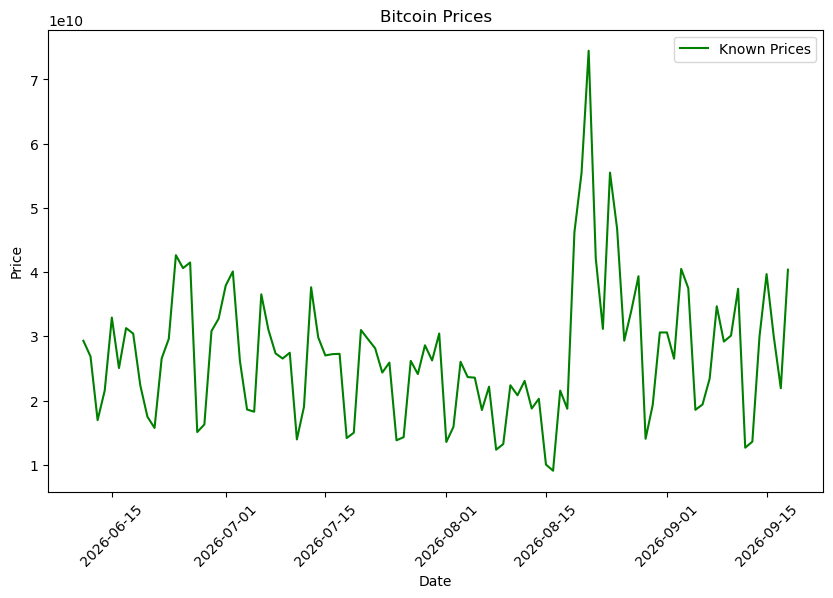

In [10]:
import matplotlib.pyplot as plt

dates = data['Date'] 

prices = data['Volume'] 

plt.figure(figsize=(10, 6))

plt.plot(dates, prices, color='green', label='Known Prices')
 
plt.xlabel('Date')
plt.ylabel('Price')
plt.title('Bitcoin Prices')

plt.xticks(rotation=45)

plt.legend()

plt.show()

In [15]:
import numpy as np
def create_dataset(serie, window_size=20):
    dataX, dataY = [] ,[]
    for i in range(len(serie)-window_size-1):
        a = serie[i:(i+window_size), 0]
        dataX.append(a)
        dataY.append([serie[i + window_size, 0]])
    return np.array(dataX) , np.array(dataY)

In [16]:
from sklearn.preprocessing import MinMaxScaler

window_size=20

closedf=data[['Volume']]
scaler=MinMaxScaler(feature_range=(0,1))
closedf=scaler.fit_transform(closedf)
  
X, y = create_dataset(closedf, window_size)

In [17]:
X

array([[0.3094493 , 0.27221926, 0.12044913, ..., 0.11014295, 0.33258886,
        0.36190789],
       [0.27221926, 0.12044913, 0.19103091, ..., 0.33258886, 0.36190789,
        0.44076271],
       [0.12044913, 0.19103091, 0.36465873, ..., 0.36190789, 0.44076271,
        0.47447646],
       ...,
       [0.30963831, 0.38156653, 0.46306306, ..., 0.05482922, 0.06925002,
        0.31851183],
       [0.38156653, 0.46306306, 0.07605836, ..., 0.06925002, 0.31851183,
        0.46813658],
       [0.46306306, 0.07605836, 0.15651378, ..., 0.31851183, 0.46813658,
        0.32071304]], shape=(79, 20))

In [19]:
y

array([[0.44076271],
       [0.47447646],
       [0.26075037],
       [0.14571176],
       [0.14049866],
       [0.42008614],
       [0.33559365],
       [0.27936565],
       [0.2670875 ],
       [0.28090949],
       [0.0745531 ],
       [0.15236385],
       [0.43687266],
       [0.31747097],
       [0.27448112],
       [0.27757956],
       [0.27831061],
       [0.07773134],
       [0.09054668],
       [0.33501932],
       [0.31308533],
       [0.29149177],
       [0.23372582],
       [0.25747426],
       [0.07245528],
       [0.07985601],
       [0.2615456 ],
       [0.23012187],
       [0.29866153],
       [0.26255813],
       [0.3266219 ],
       [0.06841536],
       [0.10432552],
       [0.25932949],
       [0.22299056],
       [0.2215567 ],
       [0.14450387],
       [0.20010586],
       [0.05001766],
       [0.06354147],
       [0.2034553 ],
       [0.17960251],
       [0.21383915],
       [0.14811525],
       [0.17127261],
       [0.01458844],
       [0.        ],
       [0.190

In [20]:
from sklearn.model_selection import train_test_split

X_train , X_test ,y_train , y_test = train_test_split(X,y,random_state=0)

In [22]:
from keras.models import Sequential
from keras.layers import Input, Dense
from keras.layers import LSTM

model = Sequential()

model.add(Input(shape=(window_size, 1)))
 
model.add(LSTM(units=32,  dropout=0.1, activation="relu"))

model.add(Dense(1 , activation="relu"))

model.compile(loss="mean_squared_error", optimizer="adam", metrics=['mse'])

In [24]:
history =model.fit(X_train , y_train , validation_data = (X_test , y_test),
                   epochs = 10 , batch_size= 8)

Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - loss: 0.1092 - mse: 0.1092 - val_loss: 0.0894 - val_mse: 0.0894
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.1092 - mse: 0.1092 - val_loss: 0.0894 - val_mse: 0.0894
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.1092 - mse: 0.1092 - val_loss: 0.0894 - val_mse: 0.0894
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.1092 - mse: 0.1092 - val_loss: 0.0894 - val_mse: 0.0894
Epoch 5/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1092 - mse: 0.1092 - val_loss: 0.0894 - val_mse: 0.0894
Epoch 6/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.1092 - mse: 0.1092 - val_loss: 0.0894 - val_mse: 0.0894
Epoch 7/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.1092 - mse: 0.1092 - val_loss: 0.0894 - val_mse: 0.0894
Epoch 8/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.1092 - mse: 0.1092 - val_loss: 0.0894 - val_mse: 0.0894
Epoch 9/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.1092 - mse: 0.1092 - 

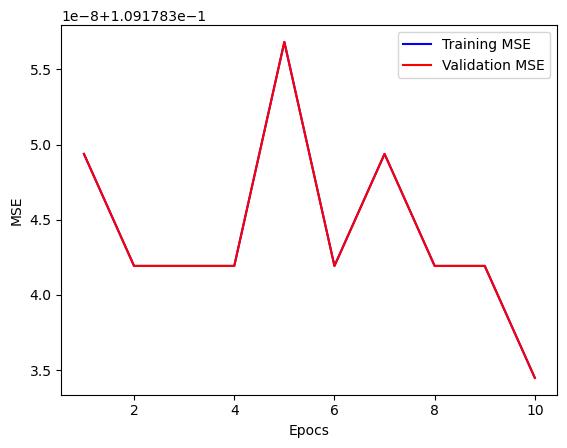

In [25]:
import matplotlib.pyplot as plt

train_mse = history.history['mse']
val_mse = history.history['val_mse']


epochs = range(1, len(train_mse) +1)
plt.plot(epochs , train_mse , 'b' ,label ='Training MSE')
plt.plot(epochs , train_mse , 'r' ,label ='Validation MSE')
plt.xlabel('Epocs')
plt.ylabel('MSE')
plt.legend()
plt.show()


In [30]:
pred_steps = 10

predicted_prices = []

X_pred = [X[-1]]

X_pred = np.array(X_pred)

for _ in range(pred_steps):
    prediction = model.predict([X_pred])

    price = prediction[0]

    predicted_prices.append(price)

    X_pred = np.append(X_pred , [price] , axis=1)

    X_pred = X_pred[:,1:]

predicted_prices = np.array(predicted_prices, dtype=object)
predicted_prices = scaler.inverse_transform(predicted_prices)
print(predicted_prices)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
[[9.07898664e+09]
 [9.07898664e+09]
 [9.07898664e+09]
 [9.07898664e+09]
 [9.07898664e+09]
 [9.07898664e+09]
 [9.07898664e+09]
 [9.07898664e+09]
 [9.07898664e+09]
 [9.07898664e+09]]


IndexError: invalid index to scalar variable.

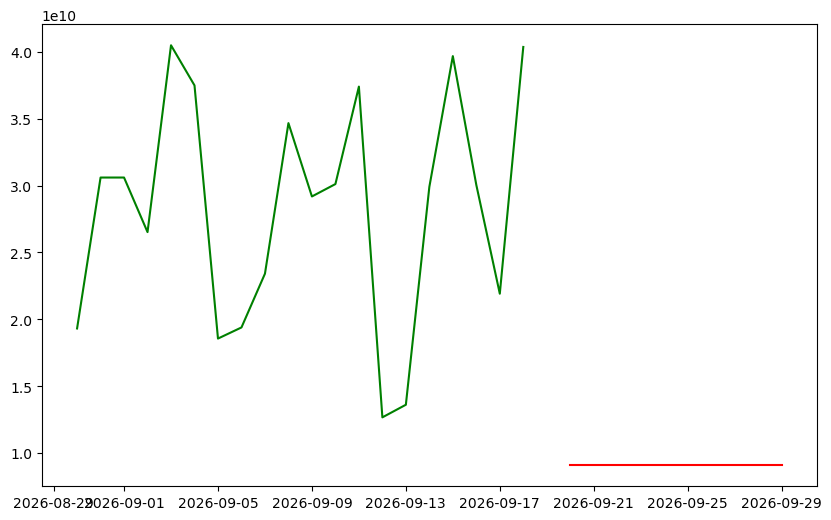

In [34]:
import matplotlib.pyplot as plt

previous_days = 20
dates_known = data["Date"].iloc[-previous_days:].values
known_prices = data["Volume"].iloc[-previous_days:].values

dates_pred = pd.date_range(
    start=today + timedelta(days=1), periods=pred_steps
).values

# Flatten predicted_prices to ensure standard 1D scalar elements
flat_predicted_prices = np.array(predicted_prices, dtype=float).flatten()

plt.figure(figsize=(10, 6))
plt.plot(dates_known, known_prices, color="green", label="Known Prices")
plt.plot(
    dates_pred, flat_predicted_prices, color="red", label="Predicted Prices"
)

# Line connecting the last known price to the first predicted price
plt.plot(
    [dates_known[-1], dates_pred[0]],
    [known_prices[-1], flat_predicted_prices[0]],
    color="blue",
)

plt.xlabel("Date")
plt.ylabel("Price")
plt.title("Bitcoin Price Prediction")
plt.xticks(rotation=45)
plt.legend()
plt.show()